# 03 · Market Basket Analysis — Apriori

**Business question:** Which products are bought together, so we can build bundles and "customers also bought" recommendations?

**Data:** cleaned transactions, **UK orders only** (most of the business, and one market keeps buying habits comparable).

**Approach:** one basket per invoice → **Apriori** → rank rules by **lift**.

- **Support(A)** = share of baskets containing A
- **Confidence(A → B)** = share of baskets with A that also contain B
- **Lift(A → B)** = Confidence / Support(B) — how many times more likely B is when A is in the basket (> 1 = real association)

## Installing apyori

In [ ]:
!pip install apyori

## Importing the libraries

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# folder for saving plots (repo: ../images, Kaggle: current folder)
IMG_DIR = '../images' if os.path.isdir('../images') else '.'

## Importing the dataset

In [3]:
# Automatically finds both CSV files under /kaggle/input (Kaggle) or ../data (local) - no manual path copying needed
files_needed = ['online_retail_09_10.csv', 'online_retail_10_11.csv']
paths = {}
for root in ['/kaggle/input', '../data', 'data']:
    for dirname, _, filenames in os.walk(root):
        for filename in filenames:
            if filename in files_needed and filename not in paths:
                paths[filename] = os.path.join(dirname, filename)

if len(paths) < 2:
    print("CSV files not found - attach the 'UCI Online Retail II' dataset under Input (Kaggle) or put them in ../data")
else:
    for f in files_needed:
        print("Found it at:", paths[f])
    # the files start with a hidden BOM character, so 'utf-8-sig' keeps the first column name clean
    dataset = pd.concat([pd.read_csv(paths[f], encoding='utf-8-sig') for f in files_needed], ignore_index=True)
    print(dataset.shape)

Found it at: ../data/online_retail_09_10.csv
Found it at: ../data/online_retail_10_11.csv


(1067371, 8)


## Cleaning the data

In [4]:
# Same cleaning as notebook 01 (explained step by step there)
dataset = dataset.drop_duplicates()                                    # also removes the overlap between the 2 files
dataset['InvoiceNo'] = dataset['InvoiceNo'].astype(str)
dataset['StockCode'] = dataset['StockCode'].astype(str)
dataset['InvoiceDate'] = pd.to_datetime(dataset['InvoiceDate'], format='%m/%d/%Y %H:%M')
dataset = dataset[~dataset['InvoiceNo'].str.startswith('C')]           # cancelled orders
dataset = dataset[(dataset['Quantity'] > 0) & (dataset['UnitPrice'] > 0)]
dataset = dataset.dropna(subset=['CustomerID'])                        # we need to know the customer
dataset = dataset[dataset['StockCode'].str.match(r'^\d')]             # keep real products (drop POST, M, BANK CHARGES...)
dataset['CustomerID'] = dataset['CustomerID'].astype(int)
dataset['Description'] = dataset['Description'].str.strip()           # remove stray spaces in product names
dataset['Revenue'] = dataset['Quantity'] * dataset['UnitPrice']
print(dataset.shape)

(776577, 9)


## Data Preprocessing — building the baskets

In [5]:
uk = dataset[dataset['Country'] == 'United Kingdom']
baskets = uk.groupby('InvoiceNo')['Description'].apply(lambda s: list(set(s.dropna())))
transactions = baskets.tolist()
print("Number of baskets:", len(transactions))
print("Average items per basket: {:.1f}".format(np.mean([len(t) for t in transactions])))
print(transactions[0][:5])

Number of baskets: 33361
Average items per basket: 20.6
['15CM CHRISTMAS GLASS BALL 20 LIGHTS', 'RECORD FRAME 7" SINGLE SIZE', 'PINK CHERRY LIGHTS', 'PINK DOUGHNUT TRINKET POT', 'SAVE THE PLANET MUG']


## Training the Apriori model on the dataset

In [6]:
from apyori import apriori
rules = apriori(transactions=transactions, min_support=0.01, min_confidence=0.3, min_lift=3, min_length=2, max_length=2)

`min_support=0.01` → the pair appears in at least 1% of UK baskets (about 330 orders). `min_confidence=0.3` and `min_lift=3` keep only strong rules.

## Visualising the results

### Displaying the first results coming directly from the output of the apriori function

In [7]:
results = list(rules)
print("Number of rules found:", len(results))
results[0]

Number of rules found: 142


RelationRecord(items=frozenset({'72 SWEETHEART FAIRY CAKE CASES', '60 TEATIME FAIRY CAKE CASES'}), support=0.015467162255328078, ordered_statistics=[OrderedStatistic(items_base=frozenset({'60 TEATIME FAIRY CAKE CASES'}), items_add=frozenset({'72 SWEETHEART FAIRY CAKE CASES'}), confidence=0.32555205047318614, lift=10.255658126379567), OrderedStatistic(items_base=frozenset({'72 SWEETHEART FAIRY CAKE CASES'}), items_add=frozenset({'60 TEATIME FAIRY CAKE CASES'}), confidence=0.4872521246458923, lift=10.255658126379567)])

### Putting the results well organised into a Pandas DataFrame

In [8]:
def inspect(results):
    lhs         = [tuple(result[2][0][0])[0] for result in results]
    rhs         = [tuple(result[2][0][1])[0] for result in results]
    supports    = [result[1] for result in results]
    confidences = [result[2][0][2] for result in results]
    lifts       = [result[2][0][3] for result in results]
    return list(zip(lhs, rhs, supports, confidences, lifts))

resultsinDataFrame = pd.DataFrame(inspect(results), columns=['Left Hand Side', 'Right Hand Side', 'Support', 'Confidence', 'Lift'])

### Displaying the results sorted by descending lifts

In [9]:
top10 = resultsinDataFrame.nlargest(n=10, columns='Lift').reset_index(drop=True)
top10.round(3)

,Left Hand Side,Right Hand Side,Support,Confidence,Lift
0,POPPY'S PLAYHOUSE KITCHEN,POPPY'S PLAYHOUSE LIVINGROOM,0.011,0.661,56.112
1,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.012,0.854,53.642
2,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,0.010,0.774,50.529
3,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN TREE CHRISTMAS SCANDINAVIAN,0.010,0.545,43.800
4,BLUE STRIPE CERAMIC DRAWER KNOB,RED STRIPE CERAMIC DRAWER KNOB,0.011,0.611,38.539
5,"KEY FOB , BACK DOOR","KEY FOB , SHED",0.012,0.725,37.401
6,FELTCRAFT PRINCESS CHARLOTTE DOLL,FELTCRAFT PRINCESS LOLA DOLL,0.010,0.605,37.210
7,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.013,0.644,35.026
8,FELTCRAFT CUSHION BUTTERFLY,FELTCRAFT CUSHION RABBIT,0.013,0.657,33.820
9,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,0.016,0.664,33.474


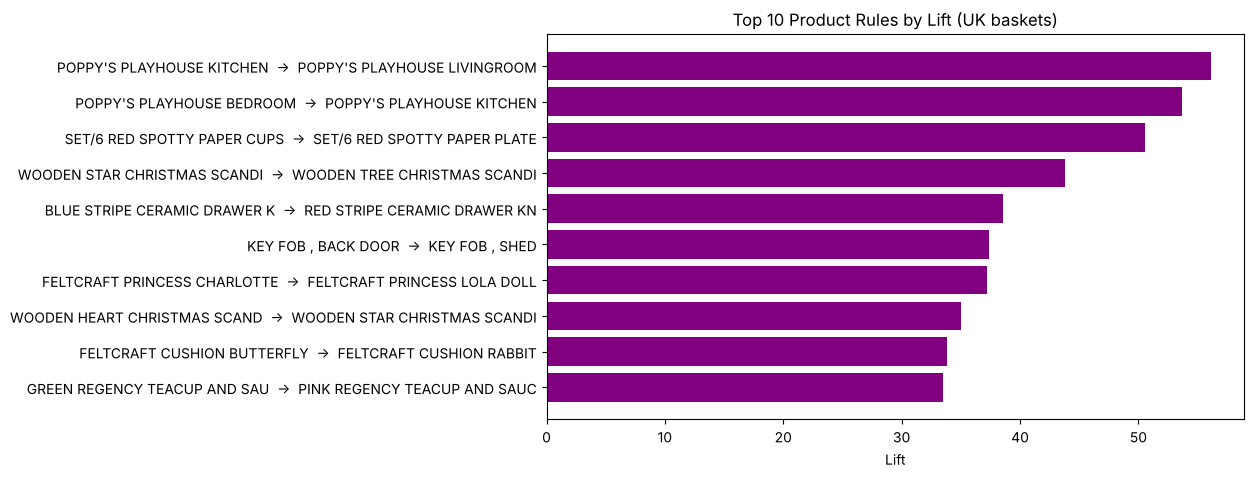

In [10]:
labels = [f"{l[:28]}  →  {r[:28]}" for l, r in zip(top10['Left Hand Side'], top10['Right Hand Side'])]
plt.figure(figsize=(9, 5))
plt.barh(labels[::-1], top10['Lift'][::-1], color='purple')
plt.title('Top 10 Product Rules by Lift (UK baskets)')
plt.xlabel('Lift')
plt.savefig(f'{IMG_DIR}/03_top_rules.png', dpi=120, bbox_inches='tight')
plt.show()

### Strongest rules by confidence (most reliable recommendations)

In [11]:
resultsinDataFrame.nlargest(n=10, columns='Confidence').reset_index(drop=True).round(3)

,Left Hand Side,Right Hand Side,Support,Confidence,Lift
0,POPPY'S PLAYHOUSE BEDROOM,POPPY'S PLAYHOUSE KITCHEN,0.012,0.854,53.642
1,PINK REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.016,0.796,28.867
2,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,0.020,0.795,28.817
3,SET/6 RED SPOTTY PAPER CUPS,SET/6 RED SPOTTY PAPER PLATES,0.010,0.774,50.529
4,PAINTED METAL PEARS ASSORTED,ASSORTED COLOUR BIRD ORNAMENT,0.015,0.735,9.791
5,CANDLEHOLDER PINK HANGING HEART,WHITE HANGING HEART T-LIGHT HOLDER,0.011,0.732,5.196
6,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,0.014,0.730,32.842
7,"KEY FOB , BACK DOOR","KEY FOB , SHED",0.012,0.725,37.401
8,RED HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,0.033,0.706,5.009
9,ALARM CLOCK BAKELIKE IVORY,ALARM CLOCK BAKELIKE RED,0.011,0.685,22.861


## Business recommendations

1. **Bundles:** the strongest pairs are **pieces of the same product family** — Poppy's Playhouse rooms, Regency teacups in different colours, matching spotty paper cups and plates, Scandinavian Christmas decorations, Feltcraft dolls. Customers collect the set, so sell them as **ready-made sets**.
2. **"Customers also bought":** use the high-confidence rules on product pages and in the basket.
3. **Stock planning:** items in strong rules sell together, so stock-outs of one hurt the other — reorder them together.

**Limitation:** rules show association, not causation, and are for UK customers only.

**Next:** 04 — predicting which customers will stop buying (churn).